In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle

from notebooks.imports import *

### Config

In [3]:
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

me_type = "global"

## Helper Functions

In [ ]:
# Define mapping from pulse_type to descriptive variable names
pulse_mapping = {
    -3: "late_left_pulse",
    -2: "middle_left_pulse",
    -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse",
    2: "middle_right_pulse",
    3: "late_right_pulse",
}


def get_pulse_coh_indices(data):
    # note indices for each pulse_type and each signed_coherence under each pulse_type
    pulse_type = data.pulse_type.unique()
    indices = {}
    for pt in pulse_type:
        indices[pt] = {}
        for sc in data.signed_coherence.unique():
            indices[pt][sc] = data[(data.pulse_type == pt) & (data.signed_coherence == sc)].agg_code.values


# Define mapping from pulse_type to descriptive variable names
def get_motion_data(trial_indices, motion_energy_dict):
    # List to store the motion data
    motion_data_array = []

    # Keep track of the max shape of the motion data
    max_shape = (0, 0, 0)  # Initialize with zeros, assuming 3 dimensions (for safety)

    for i in trial_indices:
        try:
            if i in motion_energy_dict.keys():
                motion_data_array.append(motion_energy_dict[i])
                max_shape = tuple(map(max, zip(max_shape, motion_energy_dict[i].shape)))
            else:
                print(f"Warning: Index {i} not found in motion_data_dict.")
        except Exception as e:
            print(f"Error processing index {i}: {e}")

    padded_motion_data = []
    for data in motion_data_array:
        if data.ndim == 1:
            padded_data = np.pad(data, (0, max_shape[0] - data.shape[0]), mode="constant")
        elif data.ndim == 2:
            padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1])], mode="constant")
        elif data.ndim == 3:
            padded_data = np.pad(data, [(0, max_shape[0] - data.shape[0]), (0, max_shape[1] - data.shape[1]), (0, max_shape[2] - data.shape[2])], mode="constant")
        else:
            raise ValueError(f"Unexpected number of dimensions in motion data: {data.ndim}")
        padded_motion_data.append(padded_data)

    motion_data_array = np.array(padded_motion_data)
    return motion_data_array

### Load and Preprocess data

In [ ]:
with open(Path(processed_dir, f"motion_energies_normalized/me_{me_type}.pkl"), "rb") as f:
    motion_energy_dict = pickle.load(f)

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)

data.reaction_time = (data.reaction_time * 1000).astype(int)
data = data[data.reaction_time < 3000]

# filter motion data as well
valid_keys = set(data.agg_code.values)
motion_energy_dict = {k: v for k, v in motion_energy_dict.items() if k in valid_keys}
motion_energy_array = np.array([motion_energy_dict[k] for k in data.agg_code.values])

assert len(motion_energy_array) == len(data), f"Length mismatch: {len(motion_energy_array)} vs {len(data)}"

### Kernel Calculation

$$
K(t) = E[s(t) \mid \text{choice1}] - E[s(t) \mid \text{choice2}]
$$

This defines the **psychophysical kernel** \( K(t) \) as the difference in the expected stimulus \( s(t) \) given two different choices.

- **\( E[s(t) \mid \text{choice1}] \)**: Average stimulus at time \( t \) when **choice 1** is made.
- **\( s(t) \)**: Stimulus sampled from a **stochastic function with symmetric noise** (e.g., Gaussian).
- **\( K(t) \)**: Represents how the stimulus at time \( t \) contributes to the decision.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def right_align_rows_with_nan_padding(arr):
    result = np.full_like(arr, np.nan)
    for i, row in enumerate(arr):
        valid = row[~np.isnan(row)]
        result[i, -len(valid) :] = valid
    return result


def prct_nan_threshold(arr, threshold=0.5):
    """Returns a boolean mask for columns where the NaN percentage exceeds the threshold."""
    return np.isnan(arr).mean(axis=0) > threshold


def get_experimental_kernel(condition_variable, motion_energy, alignment="stimulus_onset", nan_threshold=0.5):
    choices = [0, 1]
    max_time = motion_energy.shape[1]

    # Apply column NaN threshold before alignment
    nan_columns = prct_nan_threshold(motion_energy, nan_threshold)
    motion_energy[:, nan_columns] = np.nan

    if alignment == "response_onset":
        motion_energy = right_align_rows_with_nan_padding(motion_energy)

    condition_1 = condition_variable == 1
    condition_2 = condition_variable == 0

    right_kernel = np.nanmean(motion_energy[condition_1], axis=0) if np.any(condition_1) else np.full(max_time, np.nan)
    left_kernel = np.nanmean(motion_energy[condition_2], axis=0) if np.any(condition_2) else np.full(max_time, np.nan)

    return right_kernel - left_kernel

/tmp/ipykernel_86012/1267577875.py:32: RuntimeWarning: Mean of empty slice
  right_kernel = np.nanmean(motion_energy[condition_1], axis=0) if np.any(condition_1) else np.full(max_time, np.nan)
/tmp/ipykernel_86012/1267577875.py:33: RuntimeWarning: Mean of empty slice
  left_kernel = np.nanmean(motion_energy[condition_2], axis=0) if np.any(condition_2) else np.full(max_time, np.nan)


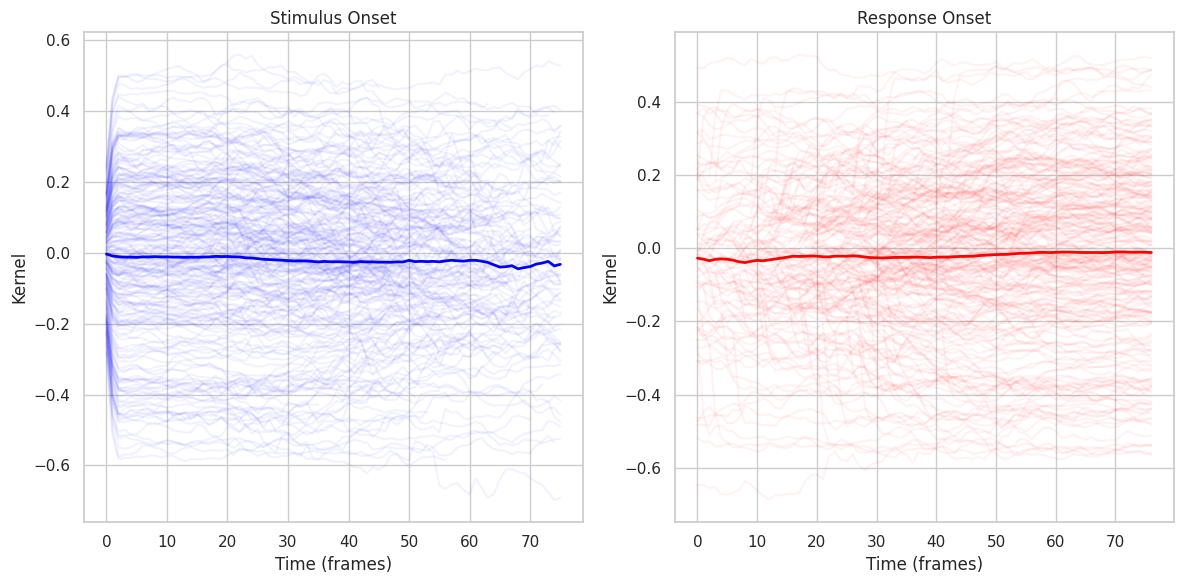

In [ ]:
def nan_column_threshold_index(arr, threshold=0.5, from_end=False):
    """Return first (or last if from_end=True) column index where NaN proportion exceeds threshold."""
    nan_ratio = np.isnan(arr).mean(axis=0)
    over_thresh = np.where(nan_ratio > threshold)[0]
    if len(over_thresh) == 0:
        return arr.shape[1] if not from_end else 0
    return over_thresh[-1] if from_end else over_thresh[0]


nan_threshold = 0.5
session_kernels = {"stimulus_onset": [], "response_onset": []}

# Aggregate per session
for idx in data.idx_session.unique():
    # session_mask = (data.idx_session == idx) & (data.pulse_type == 0) & (data.outcome == 1)
    # condition_variable = data[session_mask].choice.values

    session_mask = (data.idx_session == idx) & (data.pulse_type == 0)
    condition_variable = data[session_mask].outcome.values
    session_me = motion_energy_array[session_mask].copy()

    # session_me = get_motion_data(session_data.agg_code.values, motion_energy_dict)

    for alignment in ["stimulus_onset", "response_onset"]:
        kernel = get_experimental_kernel(condition_variable, session_me, alignment, nan_threshold)
        session_kernels[alignment].append(kernel)

# Convert to arrays and apply trimming
for alignment in ["stimulus_onset", "response_onset"]:
    kernels = np.array(session_kernels[alignment])
    if alignment == "stimulus_onset":
        end_idx = nan_column_threshold_index(kernels, threshold=0.7)
        session_kernels[alignment] = kernels[:, :end_idx]
    else:
        start_idx = nan_column_threshold_index(kernels, threshold=0.7, from_end=True)
        session_kernels[alignment] = kernels[:, start_idx:]

# === Plotting ===
fig, ax = plt.subplots(1, 2, figsize=(12, 6))


def plot_kernels(ax, kernels, title, color):
    ax.plot(kernels.T, color=color, alpha=0.05)
    ax.plot(np.nanmean(kernels, axis=0), color=color, linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("Time (frames)")
    ax.set_ylabel("Kernel")
    # ax.set_ylim([-0.5, 0.5])


plot_kernels(ax[0], session_kernels["stimulus_onset"], "Stimulus Onset", "blue")
plot_kernels(ax[1], session_kernels["response_onset"], "Response Onset", "red")

plt.tight_layout()
plt.show()